# Confidence calibration

How well the model's stated `confidence` matches how often it is right, for one `evaluate` sweep.

After https://arxiv.org/pdf/2512.16030

In [ ]:
from analysis.build_data import load_trace_df
from analysis.calibration import (
    category_accuracy_table,
    category_table,
    confidence_metrics,
    horizon_plot,
    horizon_table,
    kalshibench_metrics,
    reliability_plot,
)


In [ ]:
# one scoreable forecast per row, from every child run of the sweep (see analysis/build_data.py)
forecasts = load_trace_df("outcome-confidence", run_name="2k-balanced")

## Dataset statistics

Table 2 of the paper: the markets in the sample by category, with the share resolving to the priced outcome (see `category_table` in `analysis/calibration.py`).

In [30]:
category_table(forecasts).round(1)

,N,%,Yes%
category,,,
economics,753,29.3,42.0
elections,582,22.7,27.1
finance,433,16.9,43.4
companies,400,15.6,51.2
politics,400,15.6,25.0


## KalshiBench table

Table 4 of the paper, per model (see `kalshibench_metrics` in `analysis/calibration.py` for the columns).

Notation, over a model's $N$ forecasts: forecast $i$ names a resolution label with stated confidence $c_i$ and is correct ($a_i = 1$) when the label is the market's resolution. "Yes" is the priced outcome occurring: $y_i = 1$ when it did, $\hat{y}_i = 1$ when the model called it, and the model's probability of it is $p_i = c_i$ if $\hat{y}_i = 1$, else $1 - c_i$.

**Acc** — accuracy, in percent:

$$\mathrm{Acc} = \frac{100}{N} \sum_i a_i$$

**F1yes** — F1 of the "yes" class, the harmonic mean of precision and recall, with $TP$, $FP$ and $FN$ counting forecasts where $(\hat{y}_i, y_i)$ is $(1, 1)$, $(1, 0)$ and $(0, 1)$:

$$F_1^{\text{yes}} = \frac{2 \cdot \mathrm{precision} \cdot \mathrm{recall}}{\mathrm{precision} + \mathrm{recall}} = \frac{2\,TP}{2\,TP + FP + FN}$$

**F1** — macro F1, the unweighted mean of the two classes' F1 ($F_1^{\text{no}}$ is the same formula with "no" as the positive class):

$$F_1 = \tfrac{1}{2} \left( F_1^{\text{yes}} + F_1^{\text{no}} \right)$$

**Brier** — Brier score, the mean squared error of $p_i$ against the outcome; 0 is perfect, 0.25 is what always answering 50% scores:

$$\mathrm{BS} = \frac{1}{N} \sum_i (p_i - y_i)^2$$

**BSS** — Brier skill score against always forecasting the base rate $\bar{y} = \frac{1}{N} \sum_i y_i$, whose Brier score is $\bar{y}(1 - \bar{y})$; 1 is perfect, 0 matches the base-rate forecast, negative is worse than it:

$$\mathrm{BSS} = 1 - \frac{\mathrm{BS}}{\bar{y}\,(1 - \bar{y})}$$

**ECE** — expected calibration error. Forecasts are grouped by $c_i$ into 10 equal-width bins $B_b$, with $\mathrm{acc}(B_b)$ the mean of $a_i$ and $\mathrm{conf}(B_b)$ the mean of $c_i$ in the bin; ECE is the size-weighted average gap between them:

$$\mathrm{ECE} = \sum_b \frac{|B_b|}{N} \left| \mathrm{acc}(B_b) - \mathrm{conf}(B_b) \right|$$

**MCE** — maximum calibration error, the worst bin's gap:

$$\mathrm{MCE} = \max_b \left| \mathrm{acc}(B_b) - \mathrm{conf}(B_b) \right|$$

In [33]:
model_table = forecasts.groupby("model").apply(
    kalshibench_metrics, include_groups=False
)

In [34]:
model_table.round(3)

,N,Acc,F1,F1yes,Brier,BSS,ECE,MCE
model,,,,,,,,
claude-fable-5-1,543.0,65.930,0.531,0.286,0.211,0.106,0.031,0.062
claude-opus-4-5,1208.0,65.315,0.633,0.547,0.221,0.086,0.059,0.400
claude-opus-5-5,1619.0,70.290,0.626,0.456,0.182,0.194,0.021,0.064


## Confidence analysis

Table 5 of the paper, per model: average confidence, confidence when wrong, and the overconfidence rate above 70/80/90% (see `confidence_metrics` in `analysis/calibration.py`).

In the notation above, all in percent:

**Avg Conf** — mean stated confidence:

$$\overline{c} = \frac{100}{N} \sum_i c_i$$

**Conf_wrong** — mean stated confidence over the forecasts the model got wrong:

$$\overline{c}_{\text{wrong}} = 100 \cdot \frac{\sum_i c_i\,(1 - a_i)}{\sum_i (1 - a_i)}$$

**OCR@$\tau$** — overconfidence rate (the paper's eq. 6), the share of forecasts with confidence above $\tau$ that were wrong:

$$\mathrm{OCR}@\tau = 100 \cdot \frac{\left|\{i : c_i > \tau,\ a_i = 0\}\right|}{\left|\{i : c_i > \tau\}\right|}$$

In [ ]:
reliability = forecasts.groupby(["model", "confidence_bin"], observed=True).agg(
    n=("correct", "size"), conf=("confidence", "mean"), acc=("correct", "mean")
)

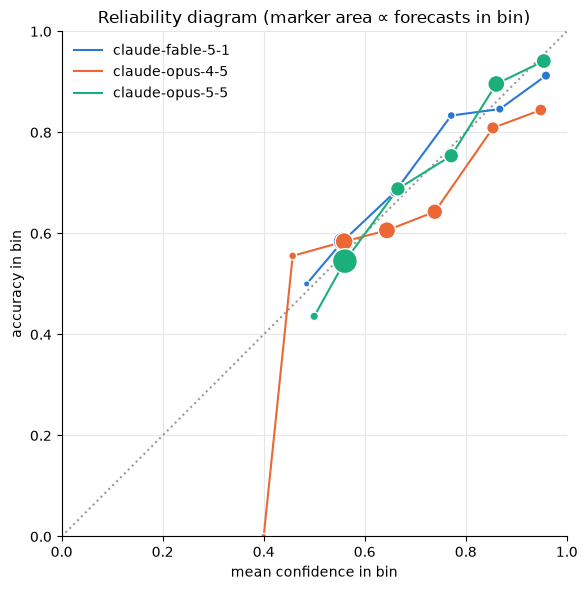

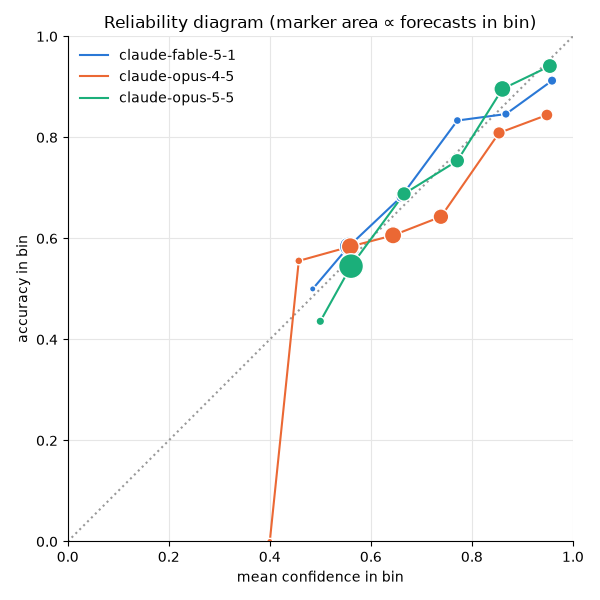

In [ ]:
reliability_plot(reliability)

## Forecast horizon

Accuracy and confidence by days from the model's training cutoff to the market's close (see `horizon_table` in `analysis/calibration.py`).

In [ ]:
horizon = horizon_table(forecasts)

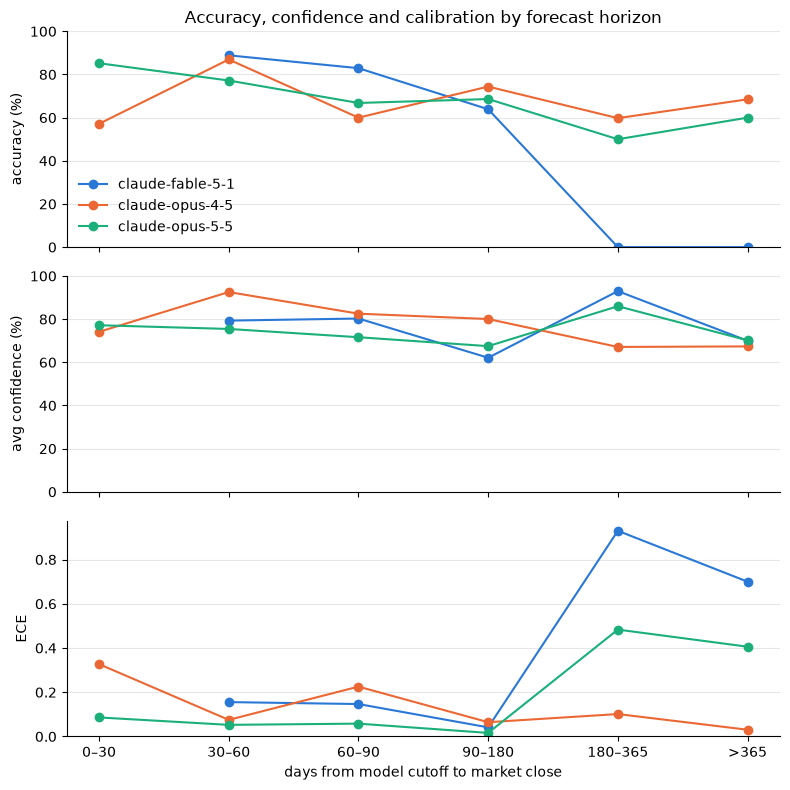

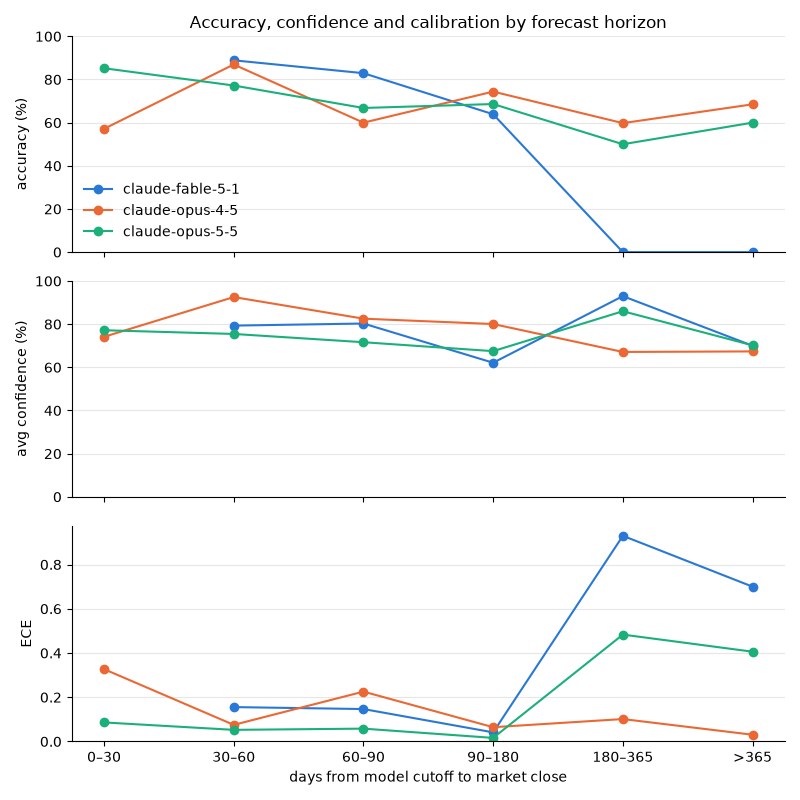

In [36]:
# solid: accuracy, dashed: average confidence; the gap is the miscalibration at that horizon
horizon_plot(horizon)

## Market category

Accuracy and confidence by model and market category (see `category_accuracy_table` in `analysis/calibration.py`).

In [40]:
by_category = category_accuracy_table(forecasts)

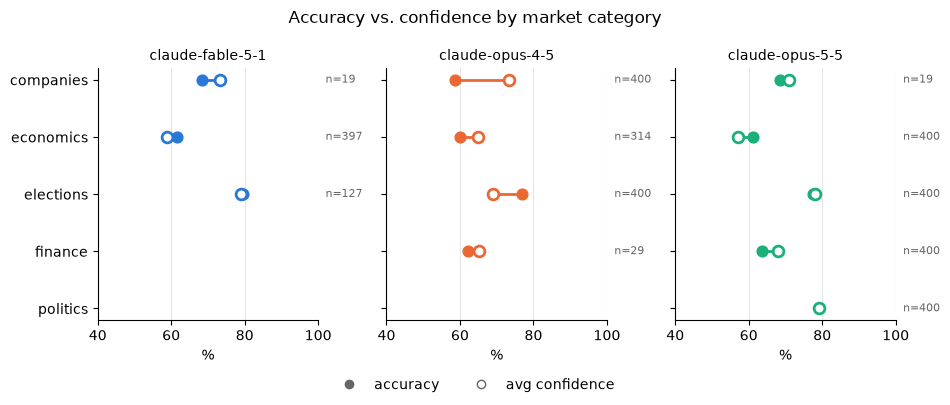

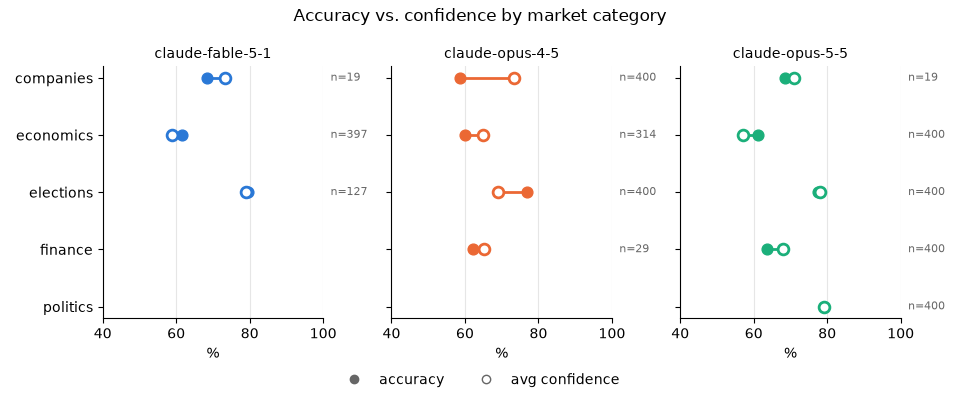

In [42]:
# filled: accuracy, hollow: average confidence; confidence to the right of accuracy is overconfidence
category_plot(by_category)